# KNN — Détection du cancer à partir de l'expression de gènes

**Dataset :** `data/gene_expression.csv` — 3000 patients, 2 variables explicatives
(`Gene One`, `Gene Two` : niveaux d'expression de deux gènes) et une cible binaire
`Cancer Present` (1 = cancer, 0 = sain).

**Objectifs :**

1. **Partie 1** — Déterminer le nombre optimal de plus proches voisins **k**.
2. **Partie 2** — Développer un KNN **from scratch** avec le k sélectionné pour prédire la présence du cancer.

---

### Rappel : l'algorithme des k plus proches voisins (KNN)

KNN est un algorithme **supervisé, non paramétrique et « paresseux »** (*lazy learning*) :
il n'apprend aucun paramètre, il **mémorise** simplement les données d'entraînement.
Pour classer un nouveau point $x$ :

1. Calculer la distance entre $x$ et **chaque** point d'entraînement $x_i$.
   Distance euclidienne : $d(x, x_i) = \sqrt{\sum_{j=1}^{p} (x_j - x_{i,j})^2}$
2. Sélectionner les **k** points les plus proches.
3. **Vote majoritaire** : la classe la plus fréquente parmi ces k voisins est la prédiction.

Le choix de **k** contrôle le compromis biais / variance :

| k petit (ex. 1) | k grand |
|---|---|
| frontière très irrégulière | frontière lisse |
| sensible au bruit → **sur-apprentissage** (variance élevée) | ignore les structures locales → **sous-apprentissage** (biais élevé) |

## 0. Importation des bibliothèques

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Utilisés UNIQUEMENT en Partie 1 (choix de k) et pour valider le modèle from scratch
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier

RANDOM_STATE = 42          # reproductibilité des résultats
np.random.seed(RANDOM_STATE)

# Couleurs des classes (fixes dans tout le notebook)
COULEURS = {0: "#2a78d6", 1: "#eb6834"}   # 0 = Sain (bleu), 1 = Cancer (orange)
NOMS = {0: "Sain (0)", 1: "Cancer (1)"}

## 1. Chargement et exploration des données

In [2]:
df = pd.read_csv("data/gene_expression.csv")
df.head()

,Gene One,Gene Two,Cancer Present
0,4.3,3.9,1
1,2.5,6.3,0
2,5.7,3.9,1
3,6.1,6.2,0
4,7.4,3.4,1


In [3]:
print("Dimensions :", df.shape)
print("\nValeurs manquantes par colonne :")
print(df.isna().sum())
df.describe()

Dimensions : (3000, 3)

Valeurs manquantes par colonne :
Gene One          0
Gene Two          0
Cancer Present    0
dtype: int64


,Gene One,Gene Two,Cancer Present
count,3000.000000,3000.000000,3000.000000
mean,5.600133,5.410467,0.500000
std,1.828388,1.729081,0.500083
min,1.000000,1.000000,0.000000
25%,4.300000,4.000000,0.000000
50%,5.600000,5.400000,0.500000
75%,6.900000,6.700000,1.000000
max,10.000000,10.000000,1.000000


**Équilibre des classes.** Si une classe était fortement majoritaire, l'accuracy seule serait
trompeuse ; on vérifie donc la répartition de la cible.

In [4]:
print(df["Cancer Present"].value_counts().rename(index=NOMS))

Cancer Present
Cancer (1)    1500
Sain (0)      1500
Name: count, dtype: int64


Les classes sont **parfaitement équilibrées** (1500 / 1500) : l'accuracy est donc une métrique
pertinente. Visualisons maintenant les deux gènes, colorés par classe.

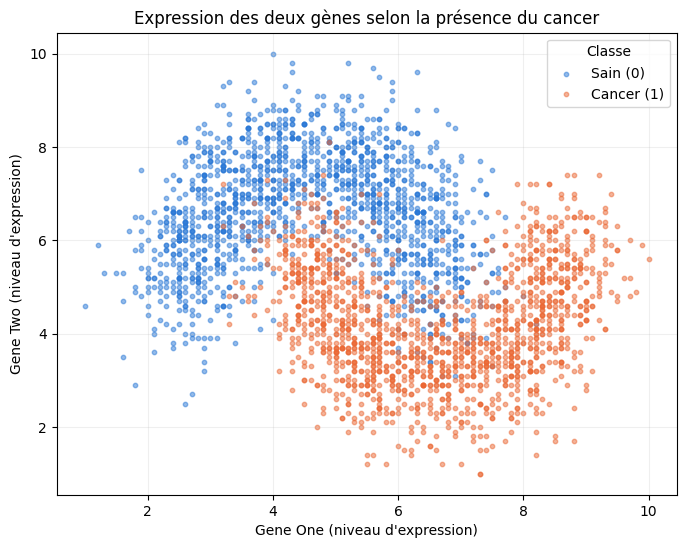

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
for c in (0, 1):
    sous = df[df["Cancer Present"] == c]
    ax.scatter(sous["Gene One"], sous["Gene Two"], s=10, alpha=0.5,
               color=COULEURS[c], label=NOMS[c])
ax.set_xlabel("Gene One (niveau d'expression)")
ax.set_ylabel("Gene Two (niveau d'expression)")
ax.set_title("Expression des deux gènes selon la présence du cancer")
ax.legend(title="Classe")
ax.grid(alpha=0.2)
plt.show()

**Observation :** les deux classes forment deux nuages bien distincts (cancer : `Gene One` élevé /
`Gene Two` faible ; sain : l'inverse) avec une **zone de chevauchement** au centre.
C'est un cas typique où KNN fonctionne bien : la classe d'un point est très probablement
celle de ses voisins. Les erreurs se concentreront dans la zone de recouvrement.

## 2. Préparation des données

### 2.1 Séparation entraînement / test
On réserve **30 %** des données pour le test final. Le paramètre `stratify=y` conserve la
proportion 50/50 dans chaque sous-ensemble. **Le jeu de test n'est jamais utilisé pour choisir k**
(sinon l'évaluation finale serait biaisée).

In [6]:
X = df[["Gene One", "Gene Two"]].values
y = df["Cancer Present"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print("Entraînement :", X_train.shape, "| Test :", X_test.shape)

Entraînement : (2100, 2) | Test : (900, 2)


### 2.2 Pourquoi standardiser ?
KNN repose sur une **distance** : une variable à grande échelle dominerait le calcul.
On applique donc la standardisation $z = \dfrac{x - \mu}{\sigma}$ afin que chaque gène
ait une moyenne 0 et un écart-type 1.

⚠️ $\mu$ et $\sigma$ sont calculés **uniquement sur le jeu d'entraînement** (pour éviter toute
fuite d'information du test). En Partie 1, cela est garanti par un `Pipeline` (le scaler est
réajusté sur chaque pli de validation croisée).

---
# Partie 1 — Détermination du nombre optimal de voisins k

### Méthode
Pour chaque valeur de k candidate, on estime la performance par **validation croisée stratifiée
à 10 plis** (*10-fold cross-validation*) sur le jeu d'entraînement :

- le jeu d'entraînement est découpé en 10 parties ;
- on entraîne sur 9 parties et on valide sur la 10ᵉ, 10 fois de suite ;
- on fait la moyenne des 10 accuracies.

Cette estimation est bien plus fiable qu'un unique découpage train/validation.

**On teste uniquement des k impairs** : en classification binaire, un k impair rend
**impossible l'égalité** lors du vote majoritaire (ex. 2 voix contre 2 avec k = 4).

In [7]:
valeurs_k = list(range(1, 52, 2))     # 1, 3, 5, ..., 51
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

cv_moyenne, cv_ecart_type, acc_train = [], [], []
for k in valeurs_k:
    modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(modele, X_train, y_train, cv=cv, scoring="accuracy")
    cv_moyenne.append(scores.mean())
    cv_ecart_type.append(scores.std())
    # accuracy sur les données d'entraînement elles-mêmes (pour illustrer le sur-apprentissage)
    acc_train.append(modele.fit(X_train, y_train).score(X_train, y_train))

resultats_k = pd.DataFrame({
    "k": valeurs_k,
    "accuracy_train": acc_train,
    "accuracy_cv": cv_moyenne,
    "ecart_type_cv": cv_ecart_type,
    "taux_erreur_cv": 1 - np.array(cv_moyenne),
})
resultats_k.round(4)

,k,accuracy_train,accuracy_cv,ecart_type_cv,taux_erreur_cv
0,1,0.9762,0.8986,0.0240,0.1014
1,3,0.9514,0.9219,0.0119,0.0781
2,5,0.9490,0.9243,0.0181,0.0757
3,7,0.9429,0.9262,0.0148,0.0738
4,9,0.9414,0.9233,0.0164,0.0767
5,11,0.9386,0.9252,0.0145,0.0748
6,13,0.9386,0.9262,0.0145,0.0738
7,15,0.9357,0.9271,0.0162,0.0729
8,17,0.9362,0.9276,0.0144,0.0724
9,19,0.9367,0.9286,0.0128,0.0714


### Méthode du coude (*elbow method*)
On trace le **taux d'erreur de validation croisée** en fonction de k. Le k optimal est celui qui
**minimise l'erreur** ; au-delà, la courbe forme un plateau (ajouter des voisins n'apporte plus rien).

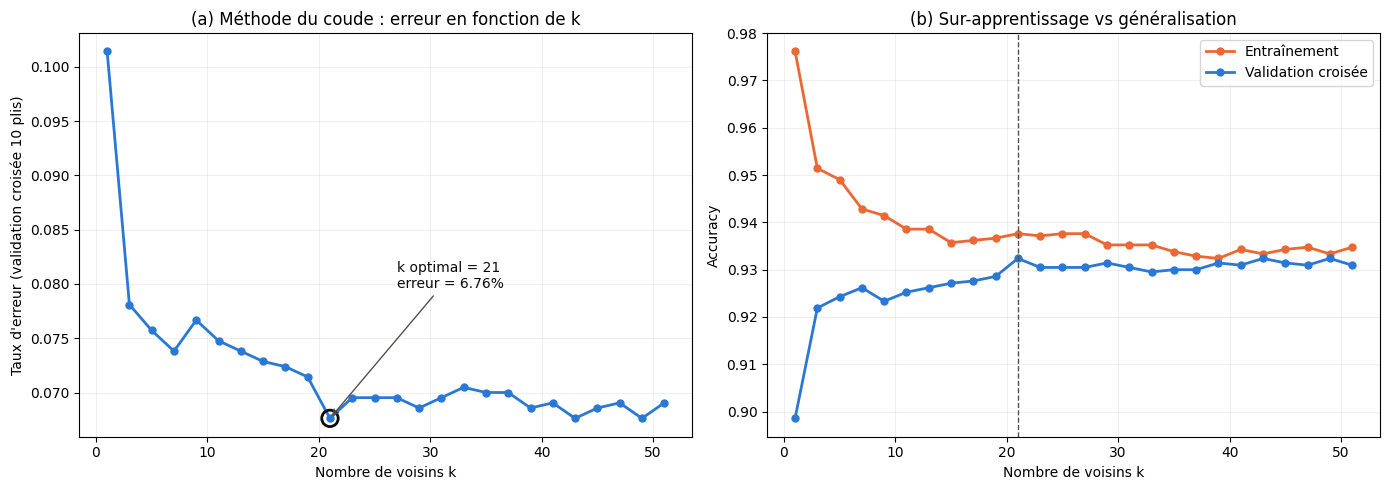

k optimal retenu : 21  (accuracy CV = 0.9324)


In [8]:
k_optimal = int(resultats_k.loc[resultats_k["accuracy_cv"].idxmax(), "k"])
erreur_min = resultats_k["taux_erreur_cv"].min()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Taux d'erreur CV vs k
ax = axes[0]
ax.plot(resultats_k["k"], resultats_k["taux_erreur_cv"], color="#2a78d6", lw=2,
        marker="o", markersize=5)
ax.scatter([k_optimal], [erreur_min], s=140, facecolors="none",
           edgecolors="#0b0b0b", linewidths=2, zorder=3)
ax.annotate(f"k optimal = {k_optimal}\nerreur = {erreur_min:.2%}",
            xy=(k_optimal, erreur_min), xytext=(k_optimal + 6, erreur_min + 0.012),
            arrowprops=dict(arrowstyle="->", color="#52514e"), color="#0b0b0b")
ax.set_xlabel("Nombre de voisins k")
ax.set_ylabel("Taux d'erreur (validation croisée 10 plis)")
ax.set_title("(a) Méthode du coude : erreur en fonction de k")
ax.grid(alpha=0.2)

# (b) Accuracy entraînement vs validation croisée
ax = axes[1]
ax.plot(resultats_k["k"], resultats_k["accuracy_train"], color="#eb6834", lw=2,
        marker="o", markersize=5, label="Entraînement")
ax.plot(resultats_k["k"], resultats_k["accuracy_cv"], color="#2a78d6", lw=2,
        marker="o", markersize=5, label="Validation croisée")
ax.axvline(k_optimal, color="#52514e", ls="--", lw=1)
ax.set_xlabel("Nombre de voisins k")
ax.set_ylabel("Accuracy")
ax.set_title("(b) Sur-apprentissage vs généralisation")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print(f"k optimal retenu : {k_optimal}  "
      f"(accuracy CV = {resultats_k['accuracy_cv'].max():.4f})")

### Interprétation

- **Graphique (b)** : avec **k = 1**, l'accuracy d'entraînement est très élevée (≈ 97,6 % : chaque point
  est son propre voisin ; elle n'atteint pas 100 % uniquement parce que certains patients ont exactement
  les mêmes valeurs de gènes mais des diagnostics différents) alors que l'accuracy de validation est la
  plus faible (≈ 89,9 %) → **sur-apprentissage** typique.
  Quand k augmente, l'écart entre les deux courbes se réduit : le modèle **généralise** mieux.
- **Graphique (a)** : l'erreur chute fortement entre k = 1 et k ≈ 5, puis diminue lentement
  jusqu'à un **minimum**, avant de se stabiliser en plateau (voire remonter légèrement :
  début du sous-apprentissage).
- Le **k optimal** est donc celui qui minimise l'erreur de validation croisée (affiché ci-dessus).
  Il est **impair**, ce qui évite les égalités lors du vote.

> Le k optimal est stocké dans la variable `k_optimal` et réutilisé dans la Partie 2.

---
# Partie 2 — KNN *from scratch*

On réimplémente **tout** le pipeline sans scikit-learn (seulement NumPy) :

1. un standardiseur (`StandardiseurScratch`) ;
2. le classifieur KNN (`KNNScratch`) : distance euclidienne, recherche des k voisins, vote majoritaire ;
3. les métriques d'évaluation (matrice de confusion, accuracy, précision, rappel, F1).

scikit-learn ne sert qu'à **vérifier** à la fin que notre implémentation donne les mêmes résultats.

## 2.1 Standardisation from scratch
$$z = \frac{x - \mu_{train}}{\sigma_{train}}$$
`fit` calcule $\mu$ et $\sigma$ sur l'entraînement ; `transform` applique la même transformation
à n'importe quel jeu de données (entraînement, test ou nouveau patient).

In [9]:
class StandardiseurScratch:
    # Standardisation : centre chaque variable (moyenne 0) et la réduit (écart-type 1).

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.moyenne_ = X.mean(axis=0)       # mu de chaque colonne
        self.ecart_type_ = X.std(axis=0)     # sigma de chaque colonne
        self.ecart_type_[self.ecart_type_ == 0] = 1.0   # évite une division par 0
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.moyenne_) / self.ecart_type_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

## 2.2 Le classifieur KNN from scratch

| Méthode | Rôle |
|---|---|
| `fit(X, y)` | « Entraînement » : mémorise simplement les données (lazy learning). |
| `_distances(x)` | Distance euclidienne entre un point `x` et **tous** les points d'entraînement. |
| `_voisins(x)` | Indices des k plus proches voisins (tri des distances). |
| `_vote(etiquettes, distances)` | Vote majoritaire ; en cas d'égalité, la classe du voisin le plus proche l'emporte. |
| `predict(X)` | Prédit la classe de chaque point de `X`. |
| `predict_proba(X)` | Proportion de voisins « cancer » → probabilité estimée. |

**Calcul vectorisé de la distance :** au lieu d'une double boucle Python (comme dans l'exemple Iris),
NumPy calcule en une seule opération $\sqrt{\sum_j (x_{train,j} - x_j)^2}$ pour toutes les lignes
de `X_train` → même résultat, beaucoup plus rapide.

In [10]:
class KNNScratch:
    # Classifieur des k plus proches voisins, implémenté sans scikit-learn.

    def __init__(self, k=5):
        if k < 1:
            raise ValueError("k doit être >= 1")
        self.k = k

    # ---------- Entraînement ----------
    def fit(self, X, y):
        # KNN n'apprend aucun paramètre : il mémorise les données d'entraînement.
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y)
        if self.k > len(self.X_train_):
            raise ValueError("k ne peut pas dépasser le nombre d'exemples d'entraînement")
        return self

    # ---------- Étape 1 : distances ----------
    def _distances(self, x):
        # Distance euclidienne entre x et chaque point d'entraînement (vectorisée).
        return np.sqrt(np.sum((self.X_train_ - x) ** 2, axis=1))

    # ---------- Étape 2 : k plus proches voisins ----------
    def _voisins(self, x):
        distances = self._distances(x)
        indices = np.argsort(distances)[: self.k]   # indices des k distances les plus petites
        return indices, distances[indices]

    # ---------- Étape 3 : vote majoritaire ----------
    @staticmethod
    def _vote(etiquettes, distances):
        comptes = Counter(etiquettes)
        max_votes = max(comptes.values())
        gagnants = [c for c, n in comptes.items() if n == max_votes]
        if len(gagnants) == 1:
            return gagnants[0]
        # Égalité (impossible avec k impair en binaire) : on garde la classe
        # du voisin le plus proche parmi les classes à égalité.
        for etiquette in etiquettes[np.argsort(distances)]:
            if etiquette in gagnants:
                return etiquette

    # ---------- Prédiction ----------
    def predict_one(self, x):
        indices, distances = self._voisins(np.asarray(x, dtype=float))
        return self._vote(self.y_train_[indices], distances)

    def predict(self, X):
        return np.array([self.predict_one(x) for x in np.asarray(X, dtype=float)])

    def predict_proba(self, X):
        # Probabilité estimée de la classe 1 (cancer) = part de voisins atteints.
        probas = []
        for x in np.asarray(X, dtype=float):
            indices, _ = self._voisins(x)
            probas.append(np.mean(self.y_train_[indices] == 1))
        return np.array(probas)

## 2.3 Entraînement et prédiction avec le k optimal

In [11]:
# 1) Standardisation (paramètres appris sur l'entraînement seulement)
scaler = StandardiseurScratch().fit(X_train)
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

# 2) Modèle KNN from scratch avec le k sélectionné en Partie 1
knn = KNNScratch(k=k_optimal).fit(X_train_std, y_train)

# 3) Prédictions sur le jeu de test
y_pred = knn.predict(X_test_std)

print(f"k utilisé : {knn.k}")
print("10 premières prédictions :", y_pred[:10])
print("10 vraies étiquettes      :", y_test[:10])

k utilisé : 21
10 premières prédictions : [0 1 1 1 0 0 0 0 0 0]
10 vraies étiquettes      : [0 1 1 1 0 0 0 0 0 0]


Tableau détaillé des prédictions (comme dans l'exemple Iris) : pour chaque patient de test,
on affiche le nombre de voisins de chaque classe.

In [12]:
nb_voisins_cancer = np.array([knn.y_train_[knn._voisins(x)[0]].sum() for x in X_test_std])

resultats = pd.DataFrame({
    "Gene One": X_test[:, 0],
    "Gene Two": X_test[:, 1],
    "voisins_sains": knn.k - nb_voisins_cancer,
    "voisins_cancer": nb_voisins_cancer,
    "classe_predite": y_pred,
    "classe_reelle": y_test,
})
resultats["correct"] = resultats["classe_predite"] == resultats["classe_reelle"]
resultats.head(15)

,Gene One,Gene Two,voisins_sains,voisins_cancer,classe_predite,classe_reelle,correct
0,4.4,6.7,13,8,0,0,True
1,6.9,3.3,0,21,1,1,True
2,7.1,3.3,0,21,1,1,True
3,8.8,6.5,0,21,1,1,True
4,4.7,7.0,14,7,0,0,True
5,4.5,8.3,21,0,0,0,True
6,4.0,6.9,21,0,0,0,True
7,7.0,6.1,20,1,0,0,True
8,5.5,8.0,21,0,0,0,True
9,6.1,5.7,18,3,0,0,True


## 2.4 Évaluation — métriques from scratch

Avec la classe positive = **cancer (1)** :

| | Prédit 0 | Prédit 1 |
|---|---|---|
| **Réel 0** | VN (vrais négatifs) | FP (faux positifs) |
| **Réel 1** | FN (faux négatifs) | VP (vrais positifs) |

- **Accuracy** $= \dfrac{VP + VN}{VP + VN + FP + FN}$ — part de prédictions correctes.
- **Précision** $= \dfrac{VP}{VP + FP}$ — parmi les patients déclarés malades, combien le sont vraiment.
- **Rappel (sensibilité)** $= \dfrac{VP}{VP + FN}$ — parmi les malades, combien sont détectés.
  **Métrique clé en médecine** : un faux négatif = un cancer non détecté.
- **F1-score** $= 2 \cdot \dfrac{\text{précision} \cdot \text{rappel}}{\text{précision} + \text{rappel}}$ — moyenne harmonique des deux.

In [13]:
def matrice_confusion(y_vrai, y_predit):
    # Retourne [[VN, FP], [FN, VP]]
    vn = np.sum((y_vrai == 0) & (y_predit == 0))
    fp = np.sum((y_vrai == 0) & (y_predit == 1))
    fn = np.sum((y_vrai == 1) & (y_predit == 0))
    vp = np.sum((y_vrai == 1) & (y_predit == 1))
    return np.array([[vn, fp], [fn, vp]])


def metriques(y_vrai, y_predit):
    (vn, fp), (fn, vp) = matrice_confusion(y_vrai, y_predit)
    accuracy = (vp + vn) / (vp + vn + fp + fn)
    precision = vp / (vp + fp) if (vp + fp) else 0.0
    rappel = vp / (vp + fn) if (vp + fn) else 0.0
    f1 = 2 * precision * rappel / (precision + rappel) if (precision + rappel) else 0.0
    return {"accuracy": accuracy, "precision": precision, "rappel": rappel, "f1": f1}


cm = matrice_confusion(y_test, y_pred)
scores_scratch = metriques(y_test, y_pred)

print("Matrice de confusion [[VN, FP], [FN, VP]] :\n", cm)
for nom, valeur in scores_scratch.items():
    print(f"{nom:>10} : {valeur:.4f}")

Matrice de confusion [[VN, FP], [FN, VP]] :
 [[414  36]
 [ 18 432]]
  accuracy : 0.9400
 precision : 0.9231
    rappel : 0.9600
        f1 : 0.9412


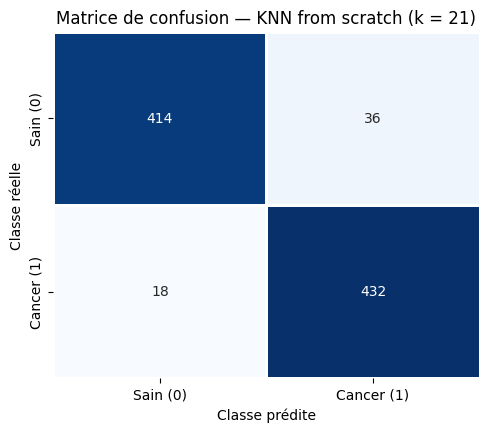

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["Sain (0)", "Cancer (1)"], yticklabels=["Sain (0)", "Cancer (1)"], ax=ax)
ax.set_xlabel("Classe prédite")
ax.set_ylabel("Classe réelle")
ax.set_title(f"Matrice de confusion — KNN from scratch (k = {k_optimal})")
plt.show()

## 2.5 Frontière de décision
On évalue le modèle sur une grille couvrant tout le plan (Gene One, Gene Two) pour visualiser
les zones où il prédit « sain » ou « cancer ». Les points du test mal classés sont entourés.

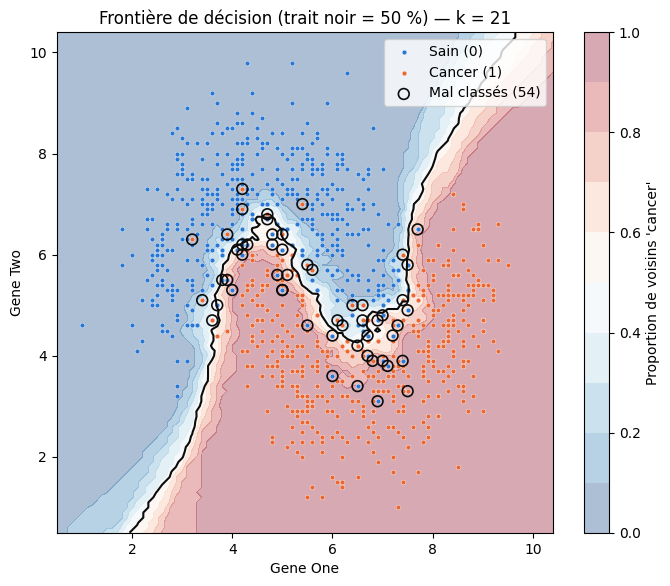

In [15]:
pas = 0.1
g1, g2 = np.meshgrid(np.arange(0.5, 10.5, pas), np.arange(0.5, 10.5, pas))
grille = np.c_[g1.ravel(), g2.ravel()]
proba_grille = knn.predict_proba(scaler.transform(grille)).reshape(g1.shape)

fig, ax = plt.subplots(figsize=(8, 6.5))
fond = ax.contourf(g1, g2, proba_grille, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.35)
ax.contour(g1, g2, proba_grille, levels=[0.5], colors="#0b0b0b", linewidths=1.5)
for c in (0, 1):
    m = y_test == c
    ax.scatter(X_test[m, 0], X_test[m, 1], s=12, color=COULEURS[c], label=NOMS[c],
               edgecolors="white", linewidths=0.3)
erreurs = y_pred != y_test
ax.scatter(X_test[erreurs, 0], X_test[erreurs, 1], s=60, facecolors="none",
           edgecolors="#0b0b0b", linewidths=1.2, label=f"Mal classés ({erreurs.sum()})")
plt.colorbar(fond, ax=ax, label="Proportion de voisins 'cancer'")
ax.set_xlabel("Gene One")
ax.set_ylabel("Gene Two")
ax.set_title(f"Frontière de décision (trait noir = 50 %) — k = {k_optimal}")
ax.legend(loc="upper right")
plt.show()

La frontière est **lisse** (grâce à un k assez grand) et sépare bien les deux nuages.
Les erreurs se situent, comme attendu, dans la **zone de chevauchement** au centre, où même un
expert ne pourrait trancher à partir de ces deux seuls gènes.

## 2.6 Validation : comparaison avec scikit-learn
Pour vérifier que l'implémentation est correcte, on entraîne `KNeighborsClassifier` de
scikit-learn avec les mêmes données et le même k, puis on compare les prédictions.

In [16]:
sk_scaler = StandardScaler().fit(X_train)
sk_knn = KNeighborsClassifier(n_neighbors=k_optimal).fit(sk_scaler.transform(X_train), y_train)
y_pred_sk = sk_knn.predict(sk_scaler.transform(X_test))

concordance = np.mean(y_pred == y_pred_sk)
comparaison = pd.DataFrame({
    "KNN from scratch": scores_scratch,
    "KNN scikit-learn": metriques(y_test, y_pred_sk),
}).round(4)
print(f"Concordance des prédictions : {concordance:.2%}")
comparaison

Concordance des prédictions : 100.00%


,KNN from scratch,KNN scikit-learn
accuracy,0.9400,0.9400
precision,0.9231,0.9231
rappel,0.9600,0.9600
f1,0.9412,0.9412


## 2.7 Prédiction pour de nouveaux patients
Utilisation du modèle final : on fournit les niveaux d'expression des deux gènes, le modèle
renvoie le diagnostic et la proportion de voisins atteints (niveau de confiance).

In [17]:
def diagnostiquer(gene_one, gene_two, modele=knn, standardiseur=scaler):
    x = standardiseur.transform([[gene_one, gene_two]])
    classe = modele.predict(x)[0]
    proba = modele.predict_proba(x)[0]
    verdict = "CANCER PRÉSENT" if classe == 1 else "Pas de cancer"
    print(f"Gene One = {gene_one:>4}, Gene Two = {gene_two:>4}  ->  {verdict:<15}"
          f"({proba:.0%} des {modele.k} voisins sont atteints)")
    return classe


nouveaux_patients = [(8.0, 3.0), (3.0, 8.0), (5.5, 5.5), (6.5, 4.5)]
for g1_val, g2_val in nouveaux_patients:
    diagnostiquer(g1_val, g2_val)

Gene One =  8.0, Gene Two =  3.0  ->  CANCER PRÉSENT (100% des 21 voisins sont atteints)
Gene One =  3.0, Gene Two =  8.0  ->  Pas de cancer  (0% des 21 voisins sont atteints)
Gene One =  5.5, Gene Two =  5.5  ->  Pas de cancer  (33% des 21 voisins sont atteints)
Gene One =  6.5, Gene Two =  4.5  ->  Pas de cancer  (33% des 21 voisins sont atteints)


---
# Conclusion

**Partie 1 — choix de k.** Le nombre optimal de voisins a été déterminé par **validation croisée
stratifiée à 10 plis** sur le jeu d'entraînement (k impairs de 1 à 51), via la méthode du coude.
- k trop petit (k = 1) → sur-apprentissage : ≈ 97,6 % sur l'entraînement mais seulement ≈ 89,9 % en validation ;
- l'erreur décroît puis atteint un plateau ; le minimum est atteint pour **k = 21**
  (accuracy de validation croisée ≈ 93,2 %, erreur ≈ 6,8 %). Il est impair, ce qui évite les égalités de vote.

**Partie 2 — KNN from scratch.** L'implémentation (standardisation, distance euclidienne,
sélection des k voisins, vote majoritaire, métriques) a été codée avec NumPy uniquement.
- Sur le jeu de test (900 patients) : **accuracy = 94,0 %**, précision = 92,3 %, **rappel = 96,0 %**,
  F1 = 94,1 % (seulement 18 cancers non détectés sur 450) ;
- elle donne **exactement les mêmes prédictions que scikit-learn** (concordance 100 %), ce qui valide l'implémentation ;
- les erreurs restantes se concentrent dans la zone où les deux classes se chevauchent :
  pour aller plus loin, il faudrait d'autres variables (gènes) plutôt qu'un autre k.

**Points méthodologiques importants :**
- standardiser les variables avant tout calcul de distance ;
- ajuster le standardiseur **uniquement** sur l'entraînement ;
- ne **jamais** utiliser le jeu de test pour choisir k.